Part 1 — Import libraries and understand the data

Step 1: Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import pandas as pd
import os


In [3]:
df = pd.read_csv("Dataset.csv")

Step 2: View the first five rows

In [4]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1


Step 3: Check rows and columns

In [5]:
df.shape

(17379, 17)

Step 4: Check column names

In [6]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')

Step 5: Check data types

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   instant     17379 non-null  int64
 1   dteday      17379 non-null  str  
 2   season      17379 non-null  str  
 3   yr          17379 non-null  str  
 4   mnth        17379 non-null  str  
 5   hr          17379 non-null  int64
 6   holiday     17379 non-null  str  
 7   weekday     17379 non-null  int64
 8   workingday  17379 non-null  str  
 9   weathersit  17379 non-null  str  
 10  temp        17379 non-null  str  
 11  atemp       17379 non-null  str  
 12  hum         17379 non-null  str  
 13  windspeed   17379 non-null  str  
 14  casual      17379 non-null  str  
 15  registered  17379 non-null  str  
 16  cnt         17379 non-null  int64
dtypes: int64(4), str(13)
memory usage: 3.3 MB


Step 6: Check missing values and duplicates

In [8]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

Step 7: View summary statistics

In [10]:
df.describe()

,instant,hr,weekday,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000
mean,8690.0000,11.546752,3.003683,189.463088
std,5017.0295,6.914405,2.005771,181.387599
min,1.0000,0.000000,0.000000,1.000000
25%,4345.5000,6.000000,1.000000,40.000000
50%,8690.0000,12.000000,3.000000,142.000000
75%,13034.5000,18.000000,5.000000,281.000000
max,17379.0000,23.000000,6.000000,977.000000


Part 2 — Data cleaning

Step 8: Replace question marks

In [11]:
df = df.replace("?", pd.NA)

Step 9: Convert numeric columns

In [12]:
cols = [
    'yr', 'mnth', 'temp', 'atemp',
    'hum', 'windspeed', 'casual', 'registered'
]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

Step 10: Check missing values again

In [13]:
df.isnull().sum()

instant        0
dteday         0
season         6
yr             1
mnth           1
hr             0
holiday        1
weekday        0
workingday     5
weathersit     4
temp          11
atemp          6
hum            6
windspeed      5
casual         1
registered     1
cnt            0
dtype: int64

Step 11: Remove rows with missing values

In [14]:
print("Before cleaning:", df.shape)

df = df.dropna().copy()

print("After cleaning:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Before cleaning: (17379, 17)
After cleaning: (17339, 17)
Missing values: 0


This removes incomplete rows from your current DataFrame, not from your original CSV file.

Part 3 — EDA graphs and time-series analysis

Step 12: Average rentals by hour

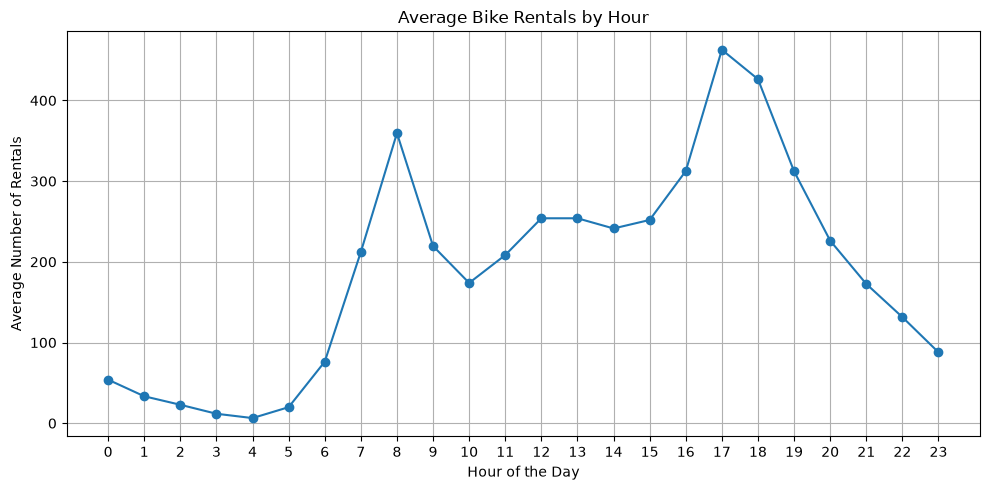

In [15]:
hourly = df.groupby('hr')['cnt'].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly.index, hourly.values, marker='o')

plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Number of Rentals')
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

Step 13: Average rentals by season

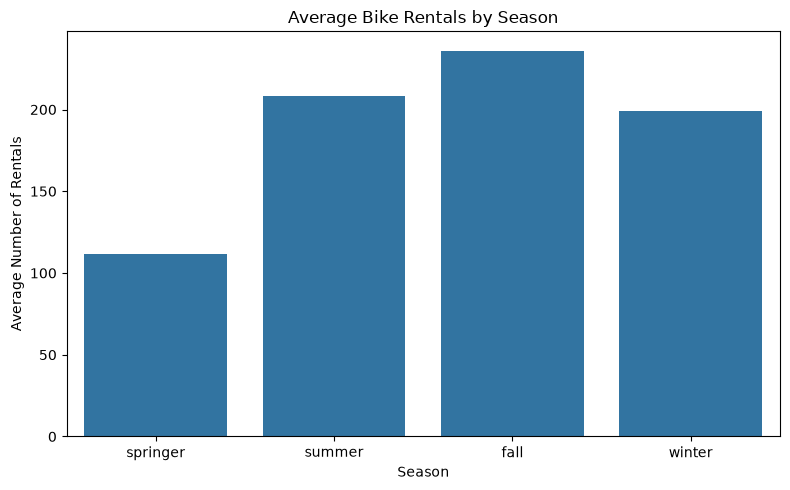

In [16]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='season', y='cnt', errorbar=None)

plt.title('Average Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Average Number of Rentals')
plt.tight_layout()
plt.show()

Step 14: Average rentals by weather

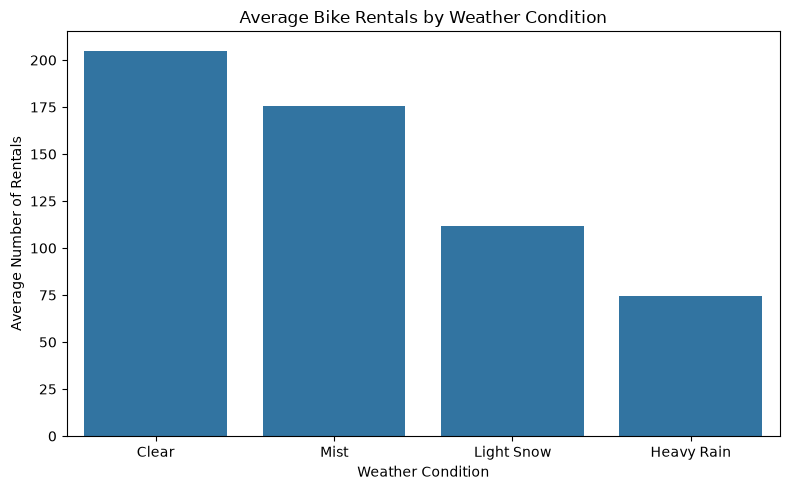

In [17]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='weathersit', y='cnt', errorbar=None)

plt.title('Average Bike Rentals by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Number of Rentals')
plt.tight_layout()
plt.show()

Step 15: Distribution of rentals

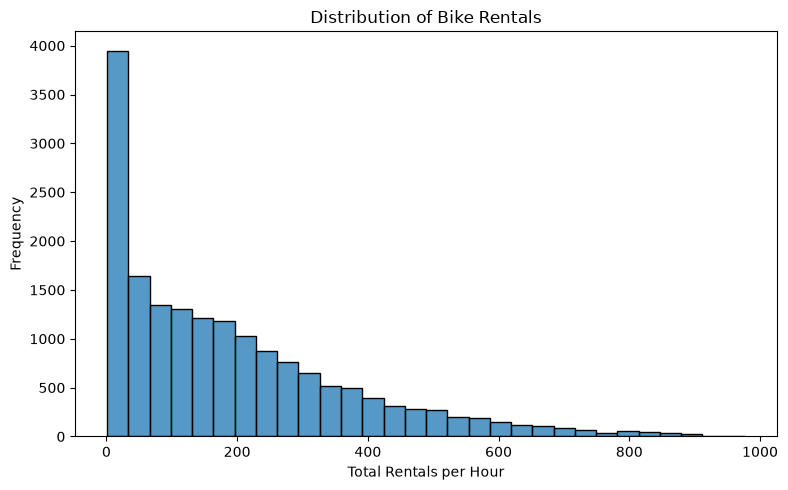

In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='cnt', bins=30)

plt.title('Distribution of Bike Rentals')
plt.xlabel('Total Rentals per Hour')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Step 16: Correlation heatmap

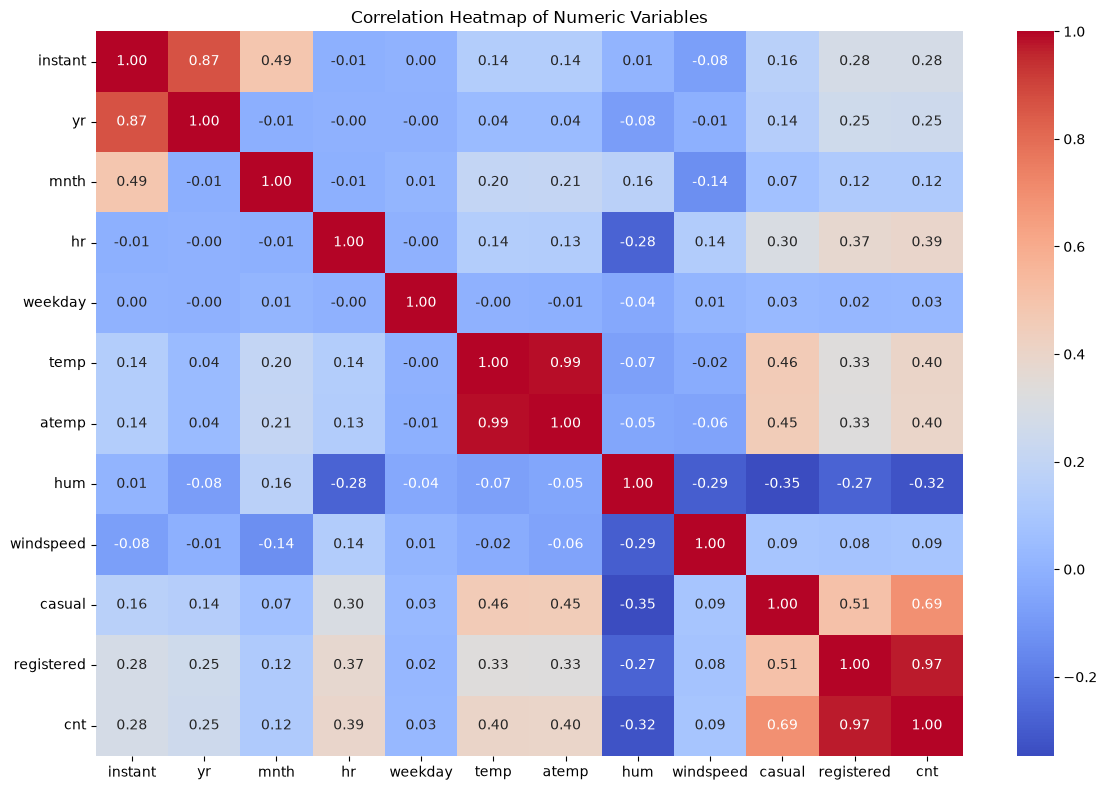

In [19]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Numeric Variables')
plt.tight_layout()
plt.show()

Step 17: Prepare the date column

In [20]:
df['dteday'] = pd.to_datetime(
    df['dteday'],
    format='%d-%m-%Y',
    errors='coerce'
)

print('Invalid dates:', df['dteday'].isna().sum())
print('Rows remaining:', len(df))

Invalid dates: 0
Rows remaining: 17339


Line 1: Convert the date into a proper date format            
Line 2: Remove rows with invalid dates

Step 18: Daily rentals over time

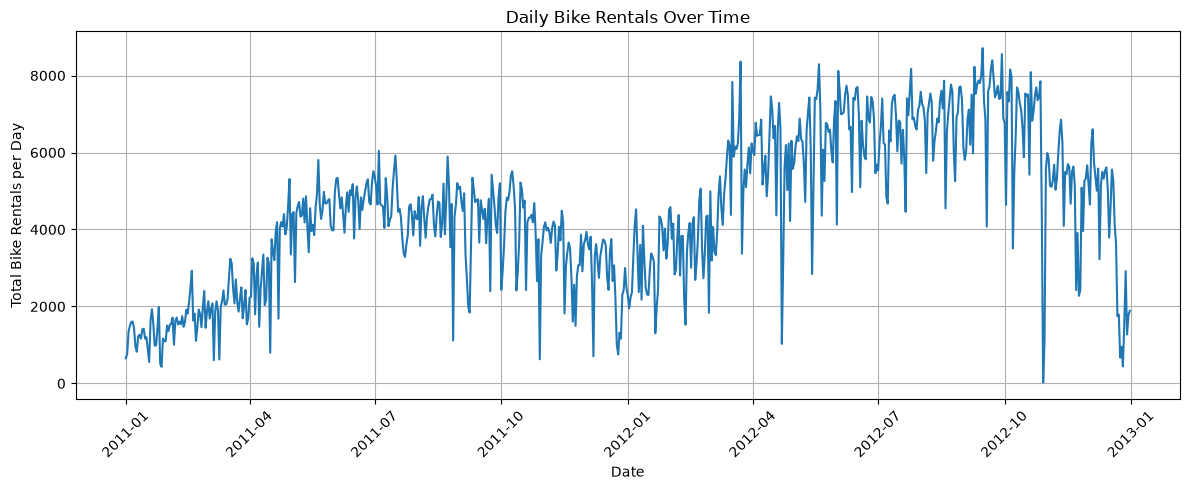

In [21]:
daily_rentals = df.groupby('dteday')['cnt'].sum().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(daily_rentals.index, daily_rentals.values)

plt.title('Daily Bike Rentals Over Time')
plt.xlabel('Date')
plt.ylabel('Total Bike Rentals per Day')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Step 19: Final checks

In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 17339 entries, 0 to 17377
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17339 non-null  int64         
 1   dteday      17339 non-null  datetime64[us]
 2   season      17339 non-null  str           
 3   yr          17339 non-null  float64       
 4   mnth        17339 non-null  float64       
 5   hr          17339 non-null  int64         
 6   holiday     17339 non-null  str           
 7   weekday     17339 non-null  int64         
 8   workingday  17339 non-null  str           
 9   weathersit  17339 non-null  str           
 10  temp        17339 non-null  float64       
 11  atemp       17339 non-null  float64       
 12  hum         17339 non-null  float64       
 13  windspeed   17339 non-null  float64       
 14  casual      17339 non-null  float64       
 15  registered  17339 non-null  float64       
 16  cnt         17339 non-null  int64     

In [23]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [24]:
df.shape

(17339, 17)

Part 1 and Part 2 cover understanding and cleaning the data; Part 3 covers visual EDA and time-series analysis.

In [25]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Select the relevant features for the regression model
# Excluding identifiers/dates, and using target variable 'cnt' as the dependent variable.
# We exclude 'casual' and 'registered' because they directly sum up to 'cnt'.
feature_cols = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']

X = df[feature_cols].copy()
y = df['cnt'].copy()

# Ensure proper numeric conversions where needed
numeric_cols = ['yr', 'mnth', 'hr', 'temp', 'atemp', 'hum', 'windspeed']
for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# 2. One-hot encode the categorical variables
# 'season', 'holiday', 'workingday', 'weathersit'
X = pd.get_dummies(X, columns=['season', 'holiday', 'workingday', 'weathersit'], drop_first=True)

# Fill any remaining NaNs with column median values
X = X.fillna(X.median())

# 3. Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialize and fit the Multiple Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict on testing set
y_pred = model.predict(X_test)

# 6. Evaluation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation Results ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}\n")

# Display coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

print("--- Model Coefficients ---")
print(coefficients.to_string(index=False))

--- Model Evaluation Results ---
Root Mean Squared Error (RMSE): 141.5892
R-squared (R2) Score: 0.3936

--- Model Coefficients ---
               Feature  Coefficient
                  temp   239.329442
                 atemp   131.992892
                    yr    78.885053
         season_winter    64.719946
 weathersit_Heavy Rain    51.948713
             windspeed    29.270613
         season_summer    26.275721
       weathersit_Mist     8.942138
       season_springer     7.962400
                    hr     7.531637
workingday_Working Day     2.670187
               weekday     1.651798
                  mnth     0.556589
           holiday_Yes   -24.610629
 weathersit_Light Snow   -24.854574
                   hum  -194.865570


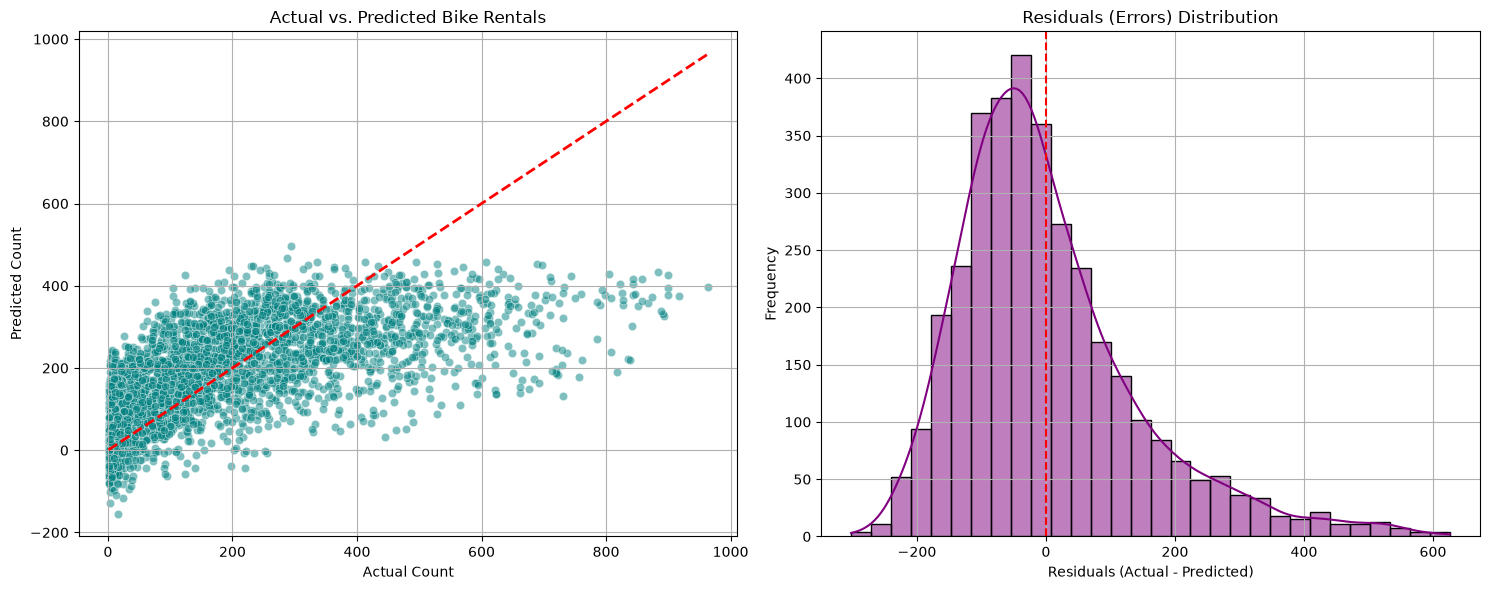

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals
residuals = y_test - y_pred

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Actual vs. Predicted
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, ax=axes[0], color='teal')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted Bike Rentals')
axes[0].set_xlabel('Actual Count')
axes[0].set_ylabel('Predicted Count')
axes[0].grid(True)

# Plot 2: Residuals Distribution
sns.histplot(residuals, kde=True, ax=axes[1], color='purple', bins=30)
axes[1].axvline(x=0, color='red', linestyle='--')
axes[1].set_title('Residuals (Errors) Distribution')
axes[1].set_xlabel('Residuals (Actual - Predicted)')
axes[1].set_ylabel('Frequency')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [27]:
# Let's engineer new features to improve predictive performance
df_engineered = df.copy()

# 1. Weekend vs. Weekday Indicator
# weekday has values 0-6. Let's create an indicator where 1 = Weekend (0 or 6) and 0 = Weekday
df_engineered['is_weekend'] = df_engineered['weekday'].apply(lambda x: 1 if x in [0, 6] else 0)

# 2. Peak Commuting Rush Hours
# Rush hours generally occur on working days between 7-9 AM and 4-6 PM (16-18)
df_engineered['workingday_numeric'] = df_engineered['workingday'].apply(lambda x: 1 if x == 'Working Day' else 0)
df_engineered['is_rush_hour'] = (((df_engineered['hr'].between(7, 9)) | (df_engineered['hr'].between(16, 18))) & (df_engineered['workingday_numeric'] == 1)).astype(int)

# 3. Temperature Categorization
# We convert 'temp' to numeric first in our df copy to categorise it safely
df_engineered['temp_numeric'] = pd.to_numeric(df_engineered['temp'], errors='coerce')

# Bin temperatures into Cold, Mild, Hot based on normalized values
def categorize_temp(temp):
    if temp < 0.3:
        return 'Cold'
    elif temp < 0.6:
        return 'Mild'
    else:
        return 'Hot'

df_engineered['temp_category'] = df_engineered['temp_numeric'].apply(categorize_temp)

# Display the new columns
display(df_engineered[['hr', 'weekday', 'workingday', 'temp', 'is_weekend', 'is_rush_hour', 'temp_category']].head(10))

,hr,weekday,workingday,temp,is_weekend,is_rush_hour,temp_category
0,0,6,No work,0.24,1,0,Cold
1,1,6,No work,0.22,1,0,Cold
3,3,6,No work,0.24,1,0,Cold
4,4,6,No work,0.24,1,0,Cold
5,5,6,No work,0.24,1,0,Cold
7,7,6,No work,0.20,1,0,Cold
8,8,6,No work,0.24,1,0,Cold
10,10,6,No work,0.38,1,0,Mild
13,13,6,No work,0.46,1,0,Mild
14,14,6,No work,0.46,1,0,Mild


In [28]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Select the original, non-engineered features
feature_cols = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']

X = df[feature_cols].copy()
y = df['cnt'].copy()

# Ensure proper numeric conversions
numeric_cols = ['yr', 'mnth', 'hr', 'temp', 'atemp', 'hum', 'windspeed']
for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# 2. One-hot encode original categorical variables
X = pd.get_dummies(X, columns=['season', 'holiday', 'workingday', 'weathersit'], drop_first=True)

# Fill any remaining NaNs with column median values
X = X.fillna(X.median())

# 3. Split the dataset (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train the baseline model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict and evaluate
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation Results (Without Feature Engineering) ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}\n")

# Display coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

print("--- Model Coefficients ---")
print(coefficients.to_string(index=False))

--- Model Evaluation Results (Without Feature Engineering) ---
Root Mean Squared Error (RMSE): 141.5892
R-squared (R2) Score: 0.3936

--- Model Coefficients ---
               Feature  Coefficient
                  temp   239.329442
                 atemp   131.992892
                    yr    78.885053
         season_winter    64.719946
 weathersit_Heavy Rain    51.948713
             windspeed    29.270613
         season_summer    26.275721
       weathersit_Mist     8.942138
       season_springer     7.962400
                    hr     7.531637
workingday_Working Day     2.670187
               weekday     1.651798
                  mnth     0.556589
           holiday_Yes   -24.610629
 weathersit_Light Snow   -24.854574
                   hum  -194.865570


### Part 5 — Model Building & Evaluation with Engineered Features
Now we will build a Multiple Linear Regression model using the engineered dataset (`df_engineered`) to assess how the new features (`is_weekend`, `is_rush_hour`, and dummy-encoded `temp_category`) impact our evaluation metrics.

In [29]:
# Ensure df exists in the current session; if not, reload and clean it from Dataset.csv
if 'df' not in globals():
    import os
    import pandas as pd
    print("df not found in scope. Reloading dataset...")

    # Try to find Dataset.csv in the directory tree
    dataset_path = None
    for root, dirs, files in os.walk('/content'):
        if 'Dataset.csv' in files:
            dataset_path = os.path.join(root, 'Dataset.csv')
            break

    if dataset_path and os.path.exists(dataset_path):
        df = pd.read_csv(dataset_path)
    else:
        raise FileNotFoundError("Dataset.csv not found in the Colab directory. Please run the upload cell (HPiNPgAyDWkP) above first.")

    # Apply the same data cleaning steps from earlier parts
    df = df.replace("?", pd.NA)
    cols = ['yr', 'mnth', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered']
    for col in cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna().copy()
    df['dteday'] = pd.to_datetime(
        df['dteday'],
        format='%d-%m-%Y',
        errors='coerce'
    )
    df = df.dropna(subset=['dteday']).copy()

# Ensure df_engineered exists
if 'df_engineered' not in globals():
    print("Creating engineered features from df...")
    df_engineered = df.copy()
    df_engineered['is_weekend'] = df_engineered['weekday'].apply(lambda x: 1 if x in [0, 6] else 0)
    df_engineered['workingday_numeric'] = df_engineered['workingday'].apply(lambda x: 1 if x == 'Working Day' else 0)
    df_engineered['is_rush_hour'] = (((df_engineered['hr'].between(7, 9)) | (df_engineered['hr'].between(16, 18))) & (df_engineered['workingday_numeric'] == 1)).astype(int)
    df_engineered['temp_numeric'] = pd.to_numeric(df_engineered['temp'], errors='coerce')
    def categorize_temp(temp):
        if temp < 0.3:
            return 'Cold'
        elif temp < 0.6:
            return 'Mild'
        else:
            return 'Hot'
    df_engineered['temp_category'] = df_engineered['temp_numeric'].apply(categorize_temp)

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Select the relevant features (including engineered ones)
feature_cols_engineered = [
    'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
    'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
    'is_weekend', 'is_rush_hour', 'temp_category'
]

X_eng = df_engineered[feature_cols_engineered].copy()
y_eng = df_engineered['cnt'].copy()

# Ensure proper numeric conversions
numeric_cols = ['yr', 'mnth', 'hr', 'temp', 'atemp', 'hum', 'windspeed', 'is_weekend', 'is_rush_hour']
for col in numeric_cols:
    X_eng[col] = pd.to_numeric(X_eng[col], errors='coerce')

# 2. One-hot encode categorical variables, including our engineered 'temp_category'
X_eng = pd.get_dummies(X_eng, columns=['season', 'holiday', 'workingday', 'weathersit', 'temp_category'], drop_first=True)

# Fill any remaining NaNs with column median values
X_eng = X_eng.fillna(X_eng.median())

# 3. Split the dataset (80% train, 20% test)
X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42)

# 4. Train the model with engineered features
model_eng = LinearRegression()
model_eng.fit(X_train_eng, y_train_eng)

# 5. Predict and evaluate
y_pred_eng = model_eng.predict(X_test_eng)
mse_eng = mean_squared_error(y_test_eng, y_pred_eng)
rmse_eng = np.sqrt(mse_eng)
r2_eng = r2_score(y_test_eng, y_pred_eng)

print("--- Model Evaluation Results (With Feature Engineering) ---")
print(f"Root Mean Squared Error (RMSE): {rmse_eng:.4f}")
print(f"R-squared (R2) Score: {r2_eng:.4f}\n")

# Display coefficients
coefficients_eng = pd.DataFrame({
    'Feature': X_eng.columns,
    'Coefficient': model_eng.coef_
}).sort_values(by='Coefficient', ascending=False)

print("--- Model Coefficients ---")
print(coefficients_eng.to_string(index=False))

--- Model Evaluation Results (With Feature Engineering) ---
Root Mean Squared Error (RMSE): 110.1879
R-squared (R2) Score: 0.6328

--- Model Coefficients ---
               Feature  Coefficient
          is_rush_hour   240.010815
                  temp   189.121116
                 atemp   155.048535
                    yr    81.320161
         season_winter    70.632106
         season_summer    31.805488
            is_weekend    27.153251
       season_springer     9.044193
             windspeed     8.363225
     temp_category_Hot     7.570083
                    hr     7.007486
       weathersit_Mist     4.835125
           holiday_Yes     2.831713
               weekday     1.965734
                  mnth     0.327264
    temp_category_Mild   -11.748116
workingday_Working Day   -29.984964
 weathersit_Light Snow   -34.517658
 weathersit_Heavy Rain   -86.587967
                   hum  -171.518655


### Download Processed Dataset for Streamlit
Run the cell below to export and download the processed dataset (`bike_sharing_processed.csv`) to your computer so you can use it in your Streamlit app.

In [30]:
# Save the processed dataset as a CSV file
df_engineered.to_csv('bike_sharing_processed.csv', index=False)

print("Dataset saved successfully!")


Dataset saved successfully!


In [31]:
import os

print(os.getcwd())

C:\Users\Admin\Documents\project Bike Rental Prediction Regression full
